In [ ]:
# Import libraries for data preprocessing
import numpy as np
import pandas as pd
from dataloader import HW2Dataset
from torch.utils.data import TensorDataset, DataLoader

# Import libraries for data visualization
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from plotting import plot_surface_2d

# Import libraries for ML
from models import RandomKitchenSinks, sweep_rks_model, MLP, mlp_sweep
import torch
import torch.nn as nn
from torch.optim import SGD
from sklearn.metrics import mean_squared_error, mean_absolute_error

a) Data visualization: You are given a pre-generated dataset with training, validation, and testing
splits. Begin by visualizing the training data. The dataset corresponds to samples (x1,x2,y) and
you can be assured that (x1,x2) are each bounded between [−3,3]. You can either generate a 2D
grid-plot where the y value is represented by a color at different (x1,x2) locations, or a 3D plot
where we visualize the response y on the z-axis.

In [13]:
# Load dataset
ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
print(ds.train.X.shape, ds.train.y.shape)
print(ds.val.X.shape, ds.val.y.shape)
print(ds.test.X.shape, ds.test.y)

(600, 2) (600,)
(200, 2) (200,)
(200, 2) None


In [14]:
# Training data
X_train = ds.train.X
y_train = ds.train.y

# Validation data
X_val = ds.val.X
y_val = ds.val.y

# Test data
X_test = ds.test.X

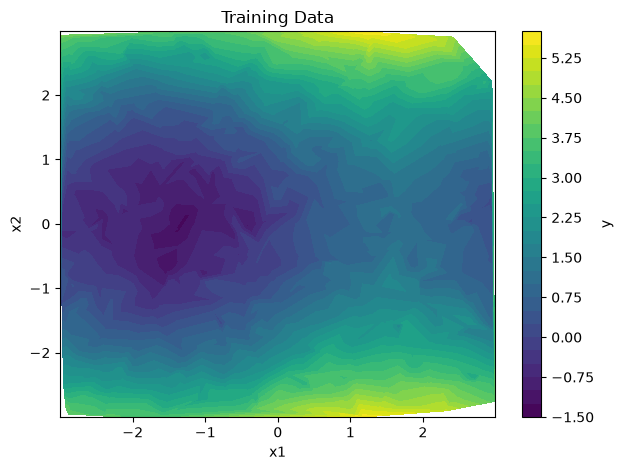

In [ ]:
# Create 2D scatterplot
plt.figure()

plt.tricontourf(
    X_train[:, 0],
    X_train[:, 1],
    y_train,
    levels=30
)

plt.title("Training Data")
plt.xlabel("x1")
plt.ylabel("x2")
plt.colorbar(label="y")
plt.tight_layout()
plt.savefig("training_data.png", dpi=300)
plt.show()

(-3.0, 3.0)

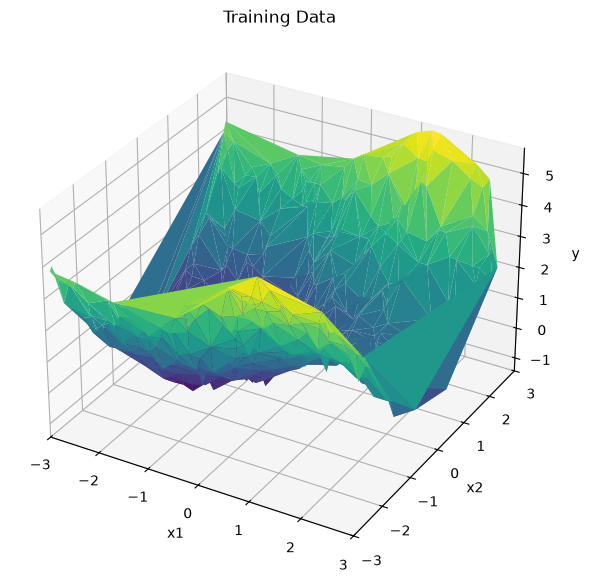

In [ ]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_trisurf(
    X_train[:, 0],
    X_train[:, 1],
    y_train,
    cmap="viridis",
    linewidth=0.2
)

ax.set_title("Training Data")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

b) Random Kitchen Sink with Ridge Regression: Implement and fit an RKS model to the given
dataset with ridge regression. You will need to vary one of the key hyperparameters while keeping
others fixed at reasonable defaults. Possible hyperparameters include:
- the number of random features h,
- the kernel scale parameter σ, or
- the ridge regularization strength λ.


Perform a hyperparameter sweep over your chosen parameter and record both the training and
validation losses (MSE). Plot the losses as a function of the hyperparameter (two plots, one for
training and one for validation loss), and select the best hyper-param based on the validation loss.

In [17]:
sweep_D = [10, 20, 50, 100, 200, 400, 600]

# Hyperparameter sweep
best_rks_model, best_rks_val_mse, best_rks_D, train_losses_rks, val_losses_rks = sweep_rks_model(
    sweep_D = sweep_D, 
    X_train = X_train,
    y_train = y_train, 
    X_val = X_val, 
    y_val = y_val
    )

D = 10: Train MSE = 0.3905, Validation MSE = 0.4298
D = 20: Train MSE = 0.0839, Validation MSE = 0.0918
D = 50: Train MSE = 0.0313, Validation MSE = 0.0379
D = 100: Train MSE = 0.0303, Validation MSE = 0.0389
D = 200: Train MSE = 0.0294, Validation MSE = 0.0427
D = 400: Train MSE = 0.0295, Validation MSE = 0.0421
D = 600: Train MSE = 0.0291, Validation MSE = 0.0447

Best hyperparameters: D = 50, sigma = 1.0, ridge_lambda = 1e-3
Best validation MSE: 0.0379


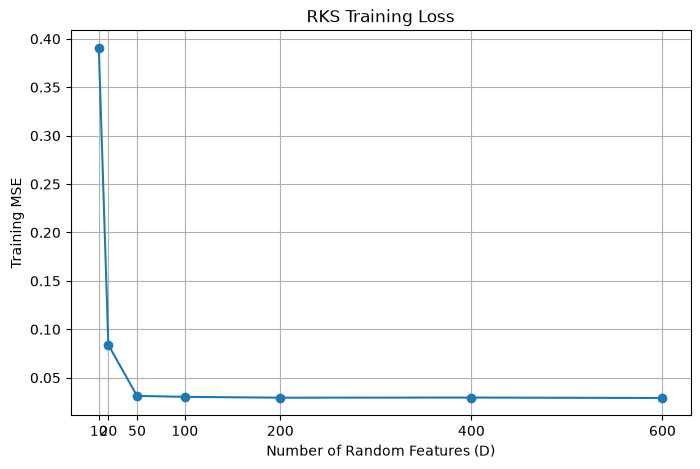

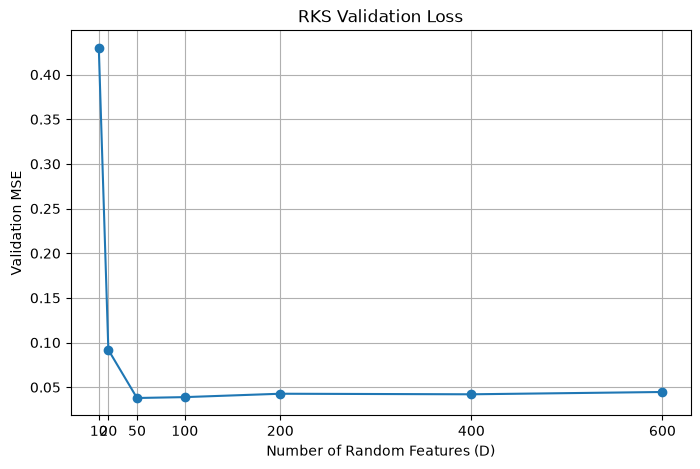

In [18]:
# Plot losses 
plt.figure(figsize=(8, 5))

plt.plot(sweep_D, train_losses_rks, marker='o')

plt.xlabel('Number of Random Features (D)')
plt.ylabel('Training MSE')
plt.title('RKS Training Loss')
plt.xticks(sweep_D)
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(sweep_D, val_losses_rks, marker='o')

plt.xlabel('Number of Random Features (D)')
plt.ylabel('Validation MSE')
plt.title('RKS Validation Loss')
plt.xticks(sweep_D)
plt.grid(True)
plt.show()

c) 1-Hidden Layer Multi-Layer Perceptron: Next, fit the same dataset using a one-hidden-layer
MLP implemented in PyTorch or Jax (the provided starter code is in PyTorch). As before, you
will choose one hyperparameter to vary (for example, the hidden layer dimension, learning rate, or
batch size) and keep other hyperparameters fixed at default values. Plot the training and validation
losses over the sweep and determine the best-performing configuration based on the validation loss.

In [19]:
sweep_values = [8, 16, 32, 64, 128, 256]

# Hyperparameter sweep
best_mlp_model, best_mlp_val_mse, best_mlp_d_hidden, train_losses_mlp, val_losses_mlp = mlp_sweep(
    sweep_values = sweep_values,
    X_train = X_train,
    y_train = y_train,
    X_val = X_val,
    y_val = y_val
)

Hidden Dim = 8: Train MSE = 3.0303, Validation MSE = 2.9193
Hidden Dim = 16: Train MSE = 3.3211, Validation MSE = 3.2677
Hidden Dim = 32: Train MSE = 3.1465, Validation MSE = 3.0570
Hidden Dim = 64: Train MSE = 3.4113, Validation MSE = 3.3104
Hidden Dim = 128: Train MSE = 4.0091, Validation MSE = 3.8755
Hidden Dim = 256: Train MSE = 4.2216, Validation MSE = 4.0775

Best hyperparameters: Hidden Dim = 8, learning rate = 1e-3, batch size = 128, activation = relu
Best validation MSE: 2.9193


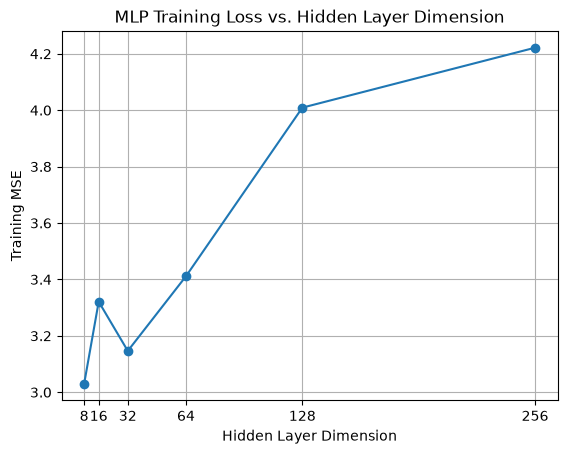

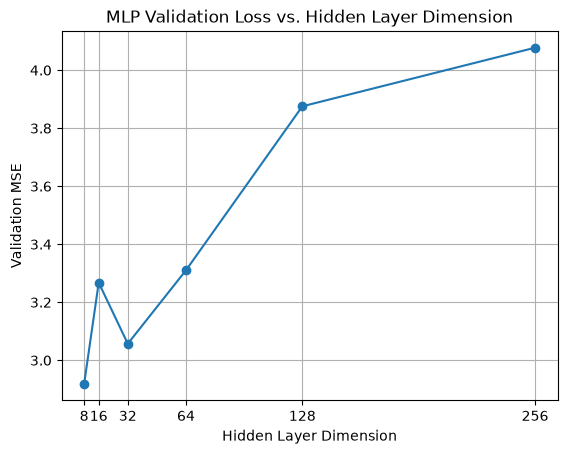

In [20]:
# Training loss
plt.figure()
plt.plot(sweep_values, train_losses_mlp, marker='o')
plt.xlabel("Hidden Layer Dimension")
plt.ylabel("Training MSE")
plt.title("MLP Training Loss vs. Hidden Layer Dimension")
plt.xticks(sweep_values)
plt.grid(True)
plt.show()

# Validation loss
plt.figure()
plt.plot(sweep_values, val_losses_mlp, marker='o')
plt.xlabel("Hidden Layer Dimension")
plt.ylabel("Validation MSE")
plt.title("MLP Validation Loss vs. Hidden Layer Dimension")
plt.xticks(sweep_values)
plt.grid(True)
plt.show()

d) Comparison and visualization: Using the best-performing hyperparameters from the previous
steps, refit both models and report the validation loss (MSE) of each. Discuss which approach
performs better and why. The provided test.csv is unlabeled (it contains only x1,x2): produce
predictions from both models on it and submit them as two CSV files, rks_test_predictions.csv
and mlp_test_predictions.csv, one prediction per row in the same order as test.csv. Finally,
visualize the fitted functions from the two models over the input space (we provide an example
function to do this). Compare these surfaces with your visualization of the training data from part
(a), and qualitatively explain how each model captures the underlying structure of the data.

In [21]:
# Initialize RKS using the best hyperparameters
rks_final = RandomKitchenSinks(
    D=best_rks_D,
    sigma=1.0,
    ridge_lambda=1e-3
)

# Fit on the training data
rks_final.fit(X_train, y_train)

# Calculate validation MSE
rks_val_pred = rks_final.predict(X_val)
rks_val_mse = np.mean((y_val - rks_val_pred) ** 2)

print(f"RKS Validation MSE: {rks_val_mse:.4f}") # want to minimize

RKS Validation MSE: 0.0379


In [22]:
# Initialize MLP using the best hyperparameters
mlp_final = MLP(
    d_in=X_train.shape[1],
    d_hidden=best_mlp_d_hidden,
    lr=1e-3,
    batch_size=128,
    activation="relu",
    device="xpu"
)

# Fit on the training data
mlp_final.fit(X_train, y_train)

# Calculate validation MSE
mlp_val_pred = mlp_final.predict(X_val)
mlp_val_mse = np.mean((y_val - mlp_val_pred) ** 2)

print(f"MLP Validation MSE: {mlp_val_mse:.4f}") # want to minimize

MLP Validation MSE: 2.8030


In [23]:
# Generate predictions
rks_test_pred = rks_final.predict(X_test)
mlp_test_pred = mlp_final.predict(X_test)

# Save predictions to CSV files
np.savetxt("rks_test_predictions.csv", rks_test_pred, delimiter=",")
np.savetxt("mlp_test_predictions.csv", mlp_test_pred, delimiter=",")

print(rks_test_pred.shape)
print(mlp_test_pred.shape)

(200,)
(200, 1)


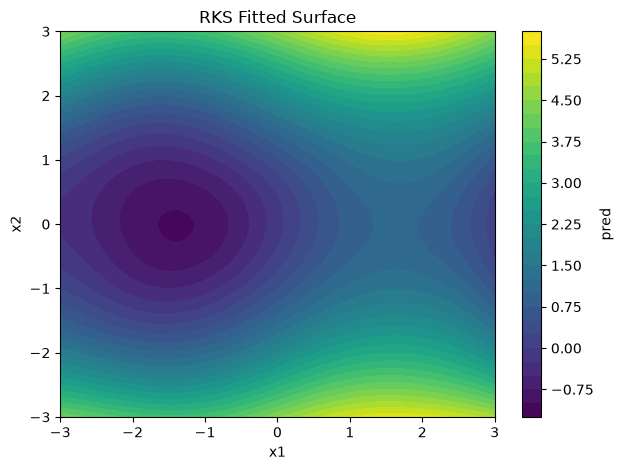

In [24]:
plot_surface_2d(
    rks_final.predict,
    xlim=(-3, 3),
    ylim=(-3, 3),
    title="RKS Fitted Surface",
    filename="rks_final_surface.png"
)

plt.show()

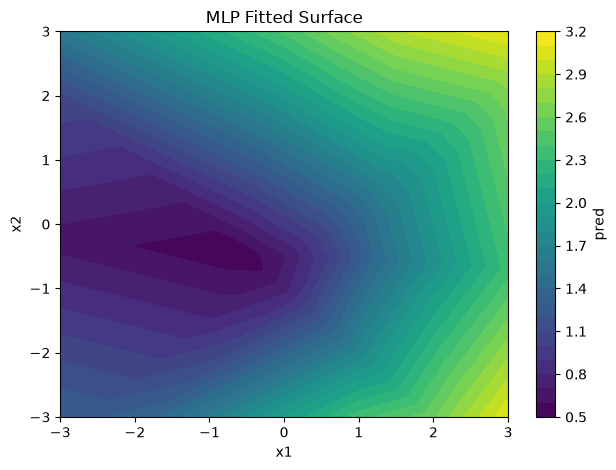

In [25]:
plot_surface_2d(
    mlp_final,
    xlim=(-3, 3),
    ylim=(-3, 3),
    title="MLP Fitted Surface",
    filename="mlp_final_surface.png"
)

plt.show()